# Predicting Customer Repeat Purchase Behaviour 

# Introduction 

Everything & Then Some, Ltd. is a diversified wholesale company whose customers exhibit different purchasing behaviours.
  
   The objective of this project is to develop a machine learning model that predicts whether a customer will make another purchase within 90 days after a given transaction.
   

# 1. Data Import and Exploration

## 1.1 Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
train = pd.read_csv("data/train.csv", index_col = "ID")
test = pd.read_csv("data/test.csv", index_col = "ID")
clientes = pd.read_csv("data/clientes.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

## 1.2 Overview of Observations

In [3]:
# First 5 rows of the train dataset:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [4]:
# Last 5 rows of the train dataset:
train.tail()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10007670,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,...,5548.20,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,-1.579719
10007671,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,...,0.00,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,-0.576883
10007672,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,...,27824.52,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,0.528377
10007673,452.07,483.60,367.54,84.53,0.0,0.00,116.06,265.159468,7.0,1.0,...,12484.20,703834,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,1.012809
10007674,951.71,982.00,773.75,177.96,0.0,0.00,208.25,224.543079,30.0,1.0,...,2256.28,438652,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 3,2019-11-23,-0.041337


In [5]:
train.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

- The train dataset has 38 columns
- Each row corresponds to one purchase

In [6]:
# To keep 3 decimal places and avoid scientific notation (e+)
pd.set_option('display.float_format','{:,.3f}'.format)

In [7]:
# Descriptive statistics of the numerical variables:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,"6,469.000",925.556,"1,334.998",0.930,188.920,476.740,"1,087.670","22,297.210"
Total Bruto,"6,469.000",886.153,"1,327.641",0.830,175.740,445.740,"1,036.700","21,578.280"
Total Liquido,"6,469.000",773.336,"1,136.356",0.760,154.380,389.910,903.370,"18,127.810"
Total Imp_,"6,469.000",152.220,225.262,0.000,29.930,79.740,184.840,"4,169.400"
Total Portes,"6,469.000",1.151,5.844,0.000,0.000,0.000,0.000,181.060
Total Desc_ Global,"6,469.000",0.350,5.117,0.000,0.000,0.000,0.000,218.490
Total Desc_ Linha,"6,469.000",112.466,289.986,0.000,0.000,13.130,92.280,"4,103.440"
Custo,"6,469.000",328.165,519.507,0.000,49.050,152.540,396.061,"7,427.401"
N_ Detalhes,"6,469.000",21.525,27.713,1.000,4.000,11.000,29.000,423.000
invoice_count_current_purchase,"6,469.000",1.066,0.311,1.000,1.000,1.000,1.000,5.000


In [8]:
col_str = ["payment_type", "salesperson", "commercial_zone", 
           "transport_method", "warehouse", "document_series"]

## 1.3. Quality of Data and Inconsistencies

### 1.3.1 Missing Values

In [10]:
train.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

- 65 rows have missing values in almost every column
- Only `customer_id` and the target, `repeat_purchase_90d`, are totally filled

### 1.3.2 Duplicated Rows

In [74]:
# To check the number of rows that have the exact same values in every columns:
print("Duplicated rows:", train.duplicated().sum())

# To check if there is any repeated ID (repeated purchase):
print("Duplicated IDs:", train.index.duplicated().sum())

Duplicated rows: 10
Duplicated IDs: 0


### 1.3.3 Impossible Values

In [82]:
num_cols = train.select_dtypes("number").columns

# To check the number of negative values per column:
(train[num_cols]< 0).sum()

Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

- The variables `spend_365d`, `prior_mean_purchase_value`, `days_since_previous_purchase` and `prior_mean_gap_days`.
- This values are impossible, since an amount of money and day counts cannot be negative.

### 1.3.4 Dates

In [90]:
print("Mínima:", train['purchase_date'].min())
print("Máxima:", train['purchase_date'].max())
print("Missing dates:", train["purchase_date"].isna().sum())

Mínima: 2015-07-11 00:00:00
Máxima: 2025-02-15 00:00:00
Missing dates: 65


### 1.3.5 Unique Values

In [9]:
for col in col_str:
    print(f"\nUnique values in {col}:")
    print(train[col].unique())


Unique values in payment_type:
<ArrowStringArray>
['Maybe Tomorrow Payment 10',  'Maybe Tomorrow Payment 7',
  'Maybe Tomorrow Payment 9', 'Maybe Tomorrow Payment 12',
                         nan,  'Maybe Tomorrow Payment 2',
  'Maybe Tomorrow Payment 8',  'Maybe Tomorrow Payment 3',
  'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 11']
Length: 10, dtype: str

Unique values in salesperson:
<ArrowStringArray>
['VLOOKUP Master 9', 'VLOOKUP Master 1', 'VLOOKUP Master 4',
                nan, 'VLOOKUP Master 2', 'VLOOKUP Master 7',
 'VLOOKUP Master 6', 'VLOOKUP Master 3', 'VLOOKUP Master 5',
 'VLOOKUP Master 8']
Length: 10, dtype: str

Unique values in commercial_zone:
<ArrowStringArray>
['Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 2',
 'Decorative Dashboard Zone 3',                           nan,
 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
Length: 6, dtype: str

Unique values in transport_method:
<ArrowStringArray>
['Maybe Tomorrow Delivery 61', 'Ma

## 1.4 Customer Structure

In [94]:
purchases_per_customer = train["customer_id"].value_counts()
print(purchases_per_customer)

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
         ... 
346493      1
956843      1
697676      1
359200      1
588088      1
Name: count, Length: 610, dtype: int64


In [98]:
# To check how many different customers there are:
print("There are", train["customer_id"].nunique(), "different customers.")

# To check how many of theese customers have more than one purchase:
print((purchases_per_customer > 1).sum(), "customers have more than one purchase done.")

# To check how many rows there is where the customer already appeared before:
print("Rows whose customer already appeared:",train["customer_id"].duplicated().sum())

There are 610 different customers.
453 customers have more than one purchase done.
Rows whose customer already appeared: 5924


- The 6534 rows (6534 purchases) in total belong to only 610 customers. 453 of them bought more than once.

## 1.5 Temporal Analisys

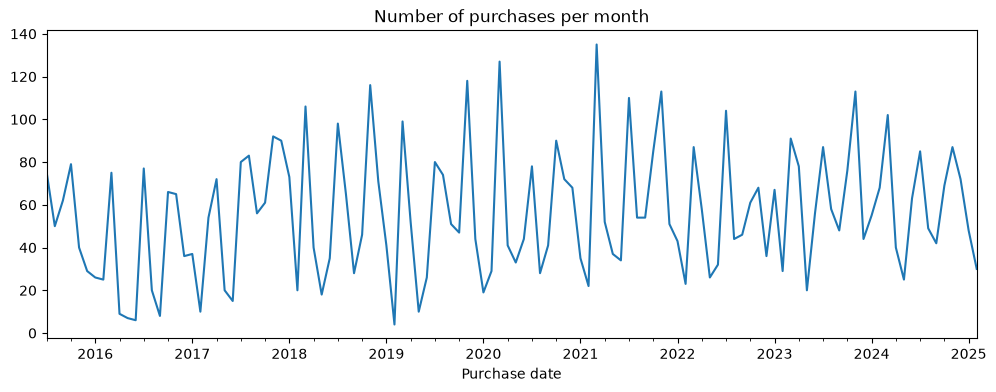

In [112]:
# Number os purchases per month:
fig, ax = plt.subplots (figsize = (12, 4))

train.set_index("purchase_date").resample("ME").size().plot(ax=ax)   # 'ME' - sets up the date for the end of the month
ax.set_title("Number of purchases per month")
ax.set_xlabel("Purchase date")

plt.show()

In [119]:
# Global rate of repeated purchases in 90 days:
print("Global rate of repeated purchases in 90 days:", ((train['repeat_purchase_90d'].mean())*100).round(2),"%")


# Rate ofcrepeated purchases in 90 days rate by month: 
for parte in [train['purchase_date'].dt.month]:
    print(train.groupby(parte)['repeat_purchase_90d'].mean(), "\n")

Global rate of repeated purchases in 90 days: 55.92 %
purchase_date
1.000    0.689
2.000    0.619
3.000    0.438
4.000    0.511
5.000    0.724
6.000    0.605
7.000    0.489
8.000    0.610
9.000    0.693
10.000   0.637
11.000   0.468
12.000   0.588
Name: repeat_purchase_90d, dtype: float64 



- The repeat rate changes a lot between months, from about 44% in march to about 72% in May. Therefore, seasonality is a variable that impacts the customer behavior.

## 1.6 Univariate Analysis

There are too many variables, so we are going to analyse one representative per type instead of all of them:
- `Total Bruto` to represent the monetary variables
- `Custo` to represent the cost of the purchases
- `spend_365d` to represent the customer history


### 1.6.1 Numerical Features

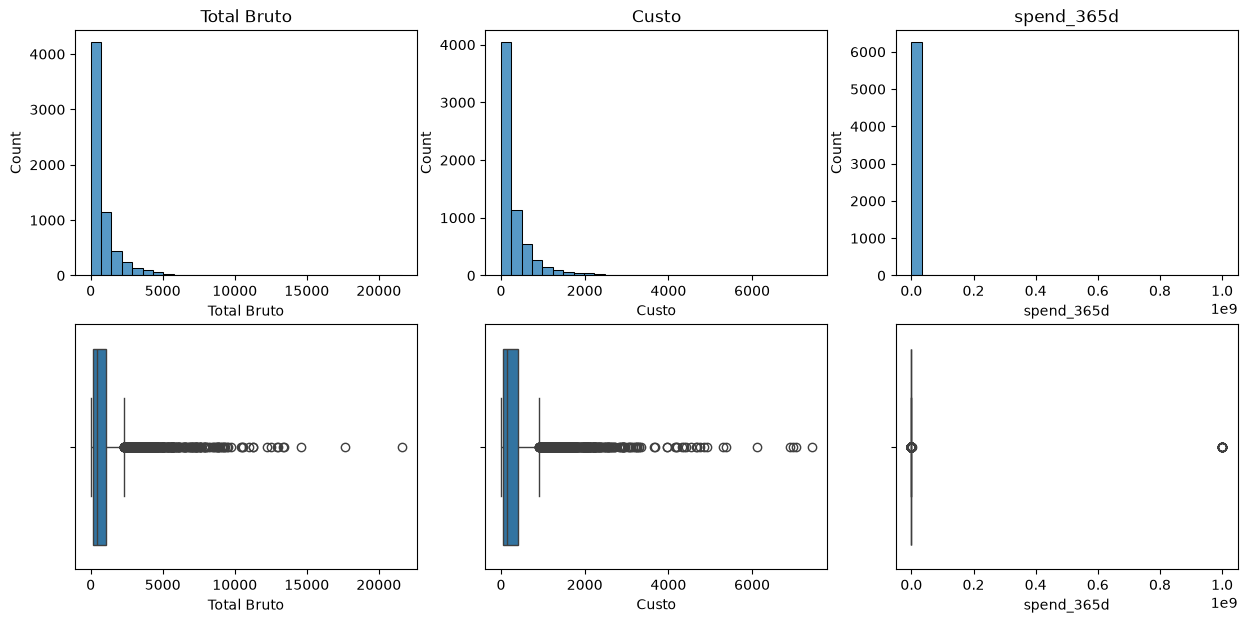

In [22]:
# Numeric features - histogram + boxplot
main_num = ["Total Bruto", "Custo", "spend_365d"]

fig, axes = plt.subplots(2, 3, figsize = (15, 7))

for i, col in enumerate(main_num):
    sns.histplot(train[col], bins = 30, ax = axes[0, i]).set_title(col)
    sns.boxplot(x = train[col], ax = axes[1, i])
    
plt.show()

- The three variables are very skewed, because most purchases are small and a few are very large.
- The outliers are probably real large purchases.

### 1.6.2 Categorical Features

In [134]:
# Lets check the number of different categories, share of missing values and weight of the most common category
cat_var = pd.DataFrame({
    "categories": train[col_str].nunique(),
    "% missing": (train[col_str].isna().mean() * 100).round(1),
    "% top category": [(train[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in col_str],
})

display(cat_var)

,categories,% missing,% top category
payment_type,9,4.000,72.800
salesperson,9,4.000,64.600
commercial_zone,5,1.000,96.800
transport_method,80,4.000,17.800
warehouse,2,4.000,99.700
document_series,3,1.000,42.300


- `warehouse` and `comercial_zone` are almost always the same value, so they carry almost no information.

## 1.7 Multivariate Analysis

We will use the Spearman correlation

In [135]:
# customer_id is only a code, so it is left out:
cols = [c for c in num_cols if c not in ["customer_id"]]

# Correlation matrix
corr = train[cols].corr(method = "spearman")
corr

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,random_noise
Total a Pagar,1.000,0.991,1.000,0.873,-0.192,-0.024,0.368,0.806,0.699,0.138,...,-0.012,-0.269,-0.213,-0.198,-0.081,-0.084,0.145,0.004,0.245,0.023
Total Bruto,0.991,1.000,0.991,0.849,-0.172,-0.019,0.459,0.788,0.698,0.143,...,-0.038,-0.233,-0.184,-0.157,-0.050,-0.050,0.169,0.036,0.267,0.021
Total Liquido,1.000,0.991,1.000,0.862,-0.193,-0.025,0.368,0.803,0.697,0.136,...,-0.009,-0.271,-0.214,-0.200,-0.082,-0.088,0.144,0.000,0.244,0.023
Total Imp_,0.873,0.849,0.862,1.000,-0.159,-0.015,0.261,0.714,0.615,0.152,...,-0.068,-0.214,-0.163,-0.143,-0.052,-0.019,0.153,0.071,0.235,0.020
Total Portes,-0.192,-0.172,-0.193,-0.159,1.000,0.083,0.066,-0.247,-0.142,0.061,...,-0.032,0.048,0.044,0.066,0.043,-0.015,-0.064,-0.050,-0.094,-0.018
Total Desc_ Global,-0.024,-0.019,-0.025,-0.015,0.083,1.000,0.009,-0.036,-0.007,0.015,...,0.102,-0.056,-0.056,-0.064,-0.071,-0.096,-0.107,-0.112,-0.120,-0.019
Total Desc_ Linha,0.368,0.459,0.368,0.261,0.066,0.009,1.000,0.313,0.379,0.078,...,-0.129,0.048,0.027,0.119,0.098,0.148,0.162,0.182,0.202,0.003
Custo,0.806,0.788,0.803,0.714,-0.247,-0.036,0.313,1.000,0.752,0.095,...,0.027,-0.246,-0.196,-0.227,-0.135,-0.108,0.069,-0.038,0.152,0.026
N_ Detalhes,0.699,0.698,0.697,0.615,-0.142,-0.007,0.379,0.752,1.000,0.113,...,0.032,-0.235,-0.203,-0.254,-0.204,-0.143,-0.026,-0.073,0.048,0.017
invoice_count_current_purchase,0.138,0.143,0.136,0.152,0.061,0.015,0.078,0.095,0.113,1.000,...,-0.083,0.043,0.046,0.063,0.075,0.082,0.104,0.097,0.115,0.012


- `Total a Pagar`, `Total Liquido` and `Total Bruto` are almost perfectly correlated (about 0.99 to 1.00). They carry redundant information, so only some of them should be kept.

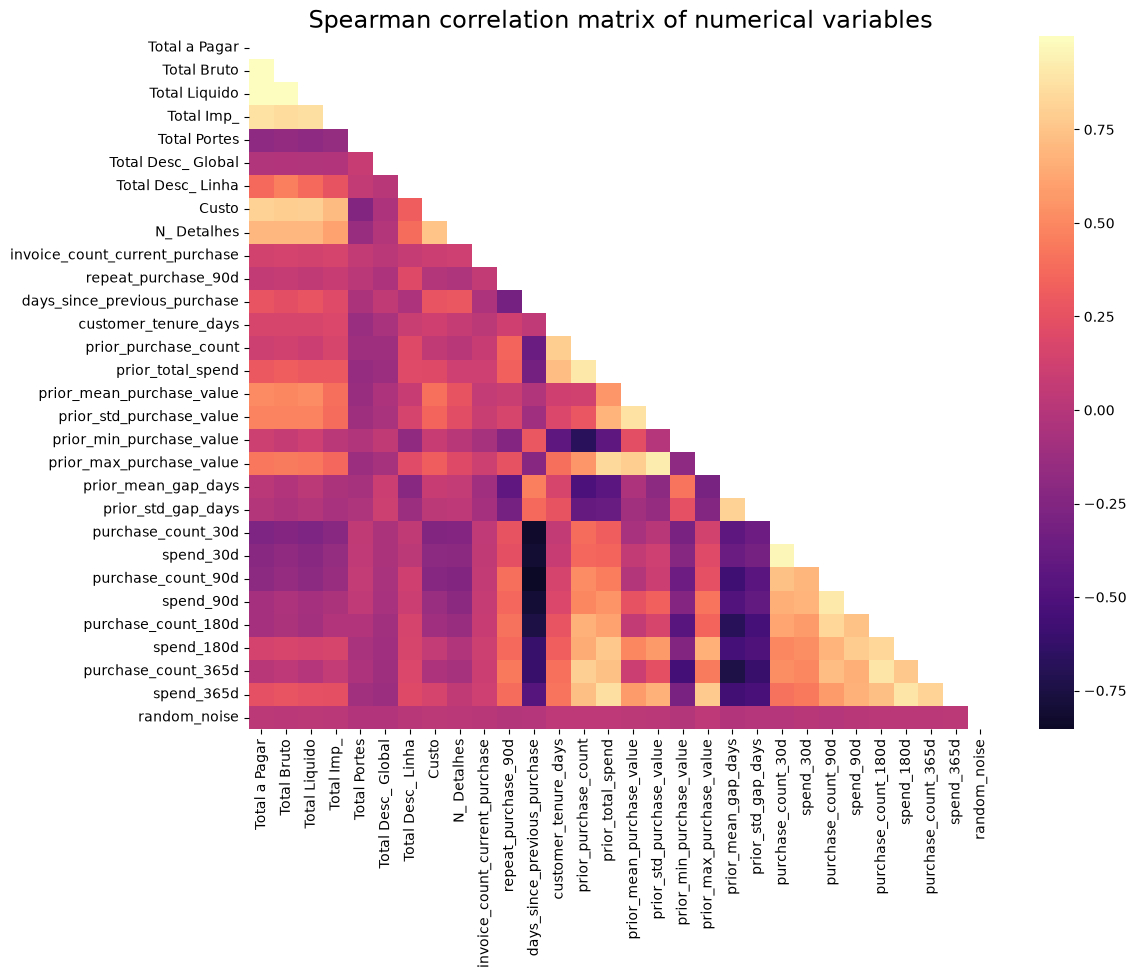

In [137]:
fig, ax = plt.subplots (figsize = (12, 9))

# To hide the upper triangle (symmetric to the lower one):
hide = np.triu(np.ones_like(corr, dtype = bool))

sns.heatmap(corr, mask = hide, cmap='magma', center = 0, annot = False)
ax.set_title("Spearman correlation matrix of numerical variables", fontsize = 17)
plt.show()

- Most variables show weak or no correlation with each other. They carry mostly independent information.
- All correlations with `repeat_purchase_90d` are weak. Therefore, no single variable is able to predict correctly this feature by itself.

In [25]:
# Correlation of each variable with the target (repeat_purchase_90d):
train[num_cols].corr()['repeat_purchase_90d'].sort_values()

prior_mean_gap_days              -0.238
prior_std_gap_days               -0.205
days_since_previous_purchase     -0.196
customer_id                      -0.112
prior_min_purchase_value         -0.099
random_noise                     -0.012
Total Desc_ Global               -0.012
Total Portes                     -0.001
prior_mean_purchase_value         0.005
spend_365d                        0.011
N_ Detalhes                       0.023
Custo                             0.048
invoice_count_current_purchase    0.049
Total Liquido                     0.073
Total a Pagar                     0.078
Total Bruto                       0.082
Total Desc_ Linha                 0.092
Total Imp_                        0.093
prior_max_purchase_value          0.100
customer_tenure_days              0.106
prior_std_purchase_value          0.134
spend_30d                         0.165
prior_total_spend                 0.262
purchase_count_30d                0.263
spend_90d                         0.269


- Individually, no variable is a strong predictor of `repeat_purchase_90d`

# 2. Clean and Pre-Process the Data

## 2.1 Empty rows and Duplicates

In [26]:
# To find the rows where every predictor is missing:
predictors = [col for col in test.columns if col != "customer_id"]

empty_rows = train[predictors].isna().all(axis = 1)
print("Rows missing:", empty_rows.sum())

Rows missing: 65


In [27]:
# To drop the empty rows:
train = train[~empty_rows]

# To check for repeated rows:
duplicated_rows = train.duplicated()
print("Duplicated rows:", duplicated_rows.sum())

# To drop the duplicated rows:
train = train[~duplicated_rows]

# To check if the train is clean:
print("Train shape after theese drops:", train.shape)

Duplicated rows: 0
Train shape after theese drops: (6469, 38)


- In part 1 we found that there were 10 duplicated rows, but all of them made part of the empty rows. Therefore, we dropped them.
- Once they were dropped, no duplicates are left!

## 2.2 Dates

In [139]:
# The test dataset writes the dates in a different format from the train dataset, so we have to convert them:

test["purchase_date"] = pd.to_datetime(test["purchase_date"], format = "%Y-%m-%d")

print("Train:", train["purchase_date"].min().date(), "to", train["purchase_date"].max().date())
print("Test:", test["purchase_date"].min().date(), "to", test["purchase_date"].max().date())

Train: 2015-07-11 to 2025-02-15
Test: 2025-05-24 to 2026-10-06


## 2.3 Impossible values

We have to check the maximum values of the single purchases made by each customer:

In [29]:
print(train["prior_mean_purchase_value"].sort_values(ascending=False).head(20))

ID
10006001   1,000,000,000.000
10007471   1,000,000,000.000
10003702   1,000,000,000.000
10006049   1,000,000,000.000
10003106   1,000,000,000.000
10007199   1,000,000,000.000
10005563   1,000,000,000.000
10002792   1,000,000,000.000
10007157   1,000,000,000.000
10002865   1,000,000,000.000
10000226   1,000,000,000.000
10006668   1,000,000,000.000
10000304   1,000,000,000.000
10006258   1,000,000,000.000
10001890   1,000,000,000.000
10004113   1,000,000,000.000
10002779          72,937.163
10001317          30,448.603
10001369          27,763.495
10007108          24,706.130
Name: prior_mean_purchase_value, dtype: float64


In [30]:
# Count the impossible values of the dataset

def count_impossible(df):
    return pd.Series({
        "prior_mean_purchase_value= 1e9":(df["prior_mean_purchase_value"]>= 1e9).sum(),
        "prior_mean_purchase_value< 0":(df["prior_mean_purchase_value"]< 0).sum(),
        "spend_365d =1e9":(df["spend_365d"]>= 1e9).sum(),
        "spend_365d< 0":(df["spend_365d"]< 0).sum(),
        "days_since_previous_purchase< 0":(df["days_since_previous_purchase"]< 0).sum(),
        "prior_mean_gap_days< 0":(df["prior_mean_gap_days"]< 0).sum(),
    })

pd.DataFrame({"train": count_impossible(train), "test":count_impossible(test)})

,train,test
prior_mean_purchase_value= 1e9,16,2
prior_mean_purchase_value< 0,16,2
spend_365d =1e9,15,2
spend_365d< 0,15,2
days_since_previous_purchase< 0,16,2
prior_mean_gap_days< 0,16,2


In [31]:
# Instead of throw away the impossibe values, lets check if the average purchase value can be recomputed:

if_valid = (train["prior_mean_purchase_value"] > 0) & (train["prior_mean_purchase_value"] < 1e9)
recomputed = train["prior_total_spend"] / train["prior_purchase_count"]

same = np.isclose(recomputed[if_valid], train.loc[if_valid, "prior_mean_purchase_value"], rtol=0.001)
print(f"% in which valid rows can be recomputed (by the mean): {same.mean():.1%}")

% in which valid rows can be recomputed (by the mean): 99.2%


In [32]:
# Now, lets fix the impossible values:
def fix_impossible_values(df):
    df = df.copy()

    # The mean is wrong when the prior mean purchase value is higher than 1e9 or lower then 0
    wrong_mean = (df["prior_mean_purchase_value"] >= 1e9)| (df["prior_mean_purchase_value"] < 0)
    df.loc[wrong_mean, "prior_mean_purchase_value"] = (
        df.loc[wrong_mean, "prior_total_spend"] / df.loc[wrong_mean, "prior_purchase_count"]
    )
    # To chnage the wrong mean value to the mean value of total spends/prior purchases

    # The spend is wrong when its value is higher than 1e9 or lower then 0, of the 365 days
    wrong_spend = (df["spend_365d"] >= 1e9) | (df["spend_365d"] < 0)
    df.loc[wrong_spend, "spend_365d"] = np.nan

    # Since days cannot be negative, we put the -4 values as nan:
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        df.loc[df[col] < 0, col] = np.nan

    return df


train = fix_impossible_values(train)
test = fix_impossible_values(test)

pd.DataFrame({"train": count_impossible(train), "test": count_impossible(test)})

,train,test
prior_mean_purchase_value= 1e9,0,0
prior_mean_purchase_value< 0,0,0
spend_365d =1e9,0,0
spend_365d< 0,0,0
days_since_previous_purchase< 0,0,0
prior_mean_gap_days< 0,0,0


In [33]:
# When prior purchase = 0, we have a new customer
for df in [train, test]:
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype(int)

train["is_first_purchase"].value_counts()

is_first_purchase
0    5866
1     603
Name: count, dtype: int64

- There are 603 customers that correspond to new ones

## 2.4 Integration of clientes.csv

In [140]:
# Check clientes content:

print("Every train customer is in clientes:", train["customer_id"].isin(clientes["customer_id"]).all())
print("Every test customer is in clientes: ", test["customer_id"].isin(clientes["customer_id"]).all())
print("Repeated customers in clientes:", clientes["customer_id"].duplicated().sum())
print()

print("Total number of customers:",clientes["customer_id"].shape)
print() 

# Missing values:
print("Missing values:\n",(clientes.isna().sum()).round(1).sort_values(ascending=False))

Every train customer is in clientes: True
Every test customer is in clientes:  True
Repeated customers in clientes: 0

Total number of customers: (1143,)

Missing values:
 customer_type          1143
street                  598
island                  578
city                    546
postal_code             170
municipality            159
commercial_region       114
postal_area              71
address                   6
country_or_region         0
customer_id               0
company_name              0
customer_since_year       0
dtype: int64


- `customer_type` is 100% empty, so it has no use.
- `street, address`, postal_code, city, company_name only identify the customer instead of describing it, and many are empty.
- `customer_since_year` is 2015 for most customers, the year the data starts, so it means "2015 or earlier".
- `customer_tenure_days` (train) already gives the same information.
- Then, we conclude that `commercial_region` and `country_or_region` are the columns worth testing!

In [35]:
clientes_2 = clientes[["customer_id", "commercial_region", "country_or_region"]]

# join() keeps the ID index of train and test 
train = train.join(clientes_2.set_index("customer_id"), on="customer_id")
test = test.join(clientes_2.set_index("customer_id"), on="customer_id")

(train.groupby("commercial_region")["repeat_purchase_90d"]
      .agg(["mean", "size"])
      .sort_values("size", ascending = False)
      .head(8)
      .round(3))

,mean,size
commercial_region,,
Region RG17: We Will See Later,0.519,4069
Region RG23: We Will See Later,0.827,560
Region RG18: We Will See Later,0.621,364
Region RG24: We Will See Later,0.944,232
Region RG29: We Will See Later,0.507,211
Region RG27: We Will See Later,0.646,192
Region RG31: We Will See Later,0.460,163
Region RG28: We Will See Later,0.437,119


- The regions behave very differently. This information shows us that it is important to use clientes.csv, because the mean varies from 44% to 94%
- This is information the train dataset doesn't have, so commercial_region will be kept!

## 2.5 New Features

In [36]:
def add_features(df):
    df = df.copy()
    df["discount_share"] = df["Total Desc_ Linha"] / df["Total Bruto"]
    df["margin_share"] = (df["Total Liquido"] - df["Custo"]) / df["Total Liquido"]
    df["value_per_detail"] = df["Total Liquido"] / df["N_ Detalhes"]
    df["overdue_ratio"] = df["days_since_previous_purchase"] / df["prior_mean_gap_days"]
    df["purchase_month"] = df["purchase_date"].dt.month.astype(str)   # a category, not a numeric variable
    return df


train = add_features(train)
test = add_features(test)

# A division by zero gives infinity, so we turn those values in nan 
train = train.replace([np.inf, -np.inf], np.nan)
test = test.replace([np.inf, -np.inf], np.nan)

| new feature | formula | idea |
|---|---|---|
| discount_share | line discount / gross total | how much of the purchase was discounted |
| margin_share | (net total - cost) / net total | how profitable the purchase was |
| value_per_detail | net total / number of details | average value of each line |
| overdue_ratio | days since previous purchase / usual gap | > 1 means the customer came back later than usual |
| purchase_month | month of purchase_date | seasonality |

## 2.6 Training and Validation Split

Since `test.csv` is in the future, we keep the **most recent 20%** of train as **validation** and use the **oldest 80%** for **training**

In [37]:
# Let's start by sort by date and then split
train = train.sort_values("purchase_date")

cut = int(len(train) * 0.8)
train_part = train.iloc[:cut]
val_part = train.iloc[cut:]

print("Training:  ", train_part["purchase_date"].min().date(), "to", train_part["purchase_date"].max().date(), "|", len(train_part), "rows")
print("Validation:", val_part["purchase_date"].min().date(), "to", val_part["purchase_date"].max().date(), "|", len(val_part), "rows")

Training:   2015-07-11 to 2023-06-17 | 5175 rows
Validation: 2023-06-17 to 2025-02-15 | 1294 rows


In [38]:
# Separate the target and remove the columns that will not be features:
## X - what the model uses to learn
## y - what the model uses to answer

target = "repeat_purchase_90d"
not_features = [target, "customer_id", "purchase_date"]

X_train = train_part.drop(columns=not_features)
y_train = train_part[target]

X_val = val_part.drop(columns=not_features)
y_val = val_part[target]

X_test = test.drop(columns=["customer_id", "purchase_date"])

print(X_train.shape, X_val.shape, X_test.shape)

(5175, 43) (1294, 43) (986, 43)


In [39]:
# Sort the columns in 3 groups, because each one will be treated differently

# Categorical column:
cat_cols = ["payment_type", "salesperson", "commercial_zone", "transport_method",
            "warehouse", "document_series", "commercial_region", "country_or_region", "purchase_month"]

# First Purchases column (new customers):
binary_cols = ["is_first_purchase"]

# Numeric column:
num_cols = [col for col in X_train.columns if col not in cat_cols + binary_cols]

# In strongly right-skewed columns (skew > 1) with no negative values, we have to put a log 
## The skew must be measured on the training rows only
skew = X_train[num_cols].skew()
log_cols = [col for col in num_cols if skew[col] > 1 and X_train[col].min() >= 0]
other_num_cols = [col for col in num_cols if col not in log_cols]

print("Log + scale:", len(log_cols), "columns")
print("Scale only: ", other_num_cols)

Log + scale: 30 columns
Scale only:  ['customer_tenure_days', 'random_noise', 'margin_share']


In [40]:
# Build the preprocessor with one pipeline for each group

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

log_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

num_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist",
                             sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("log", log_pipeline, log_cols),
    ("num", num_pipeline, other_num_cols),
    ("cat", cat_pipeline, cat_cols),
    ("binary", "passthrough", binary_cols),
])

# Return DataFrames with column names instead of plain arrays:
preprocessor = preprocessor.set_output(transform="pandas")

In [41]:
# Put the rules and what it's learned into rolling, to understand if there is valid transformation and testing

# The model will learn categories, means, standard deviations and medians:
X_train_prep = preprocessor.fit_transform(X_train)

# The model will only apply what it learned:
X_val_prep = preprocessor.transform(X_val)    

X_test_prep = preprocessor.transform(X_test)

print("Shapes:", X_train_prep.shape, X_val_prep.shape, X_test_prep.shape)
print("Missing values left:", X_train_prep.isna().sum().sum(), X_val_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())

Shapes: (5175, 111) (1294, 111) (986, 111)
Missing values left: 0 0 0


In [42]:
# Example that shows that the training columns now have mean 0 and standard deviation 1
X_train_prep[["log__Total a Pagar", "log__purchase_count_365d", "num__customer_tenure_days"]].describe().round(2)

,log__Total a Pagar,log__purchase_count_365d,num__customer_tenure_days
count,"5,175.000","5,175.000","5,175.000"
mean,0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-3.940,-1.520,-1.190
25%,-0.610,-0.810,-0.870
50%,0.080,-0.100,-0.190
75%,0.690,0.600,0.740
max,2.650,2.670,2.660


# 3. Feature Selection

After prepocessing we have 111 columns. Many carry the same information (the monetary totals are almost copies of each other) and some carry none. Fewer, better columns make the model easier to explain and less likely to learn noise.

## 3.1. Identifier-like variables and random noise

In [43]:
from sklearn.metrics import roc_auc_score

print("customer_id  AUC:", round(roc_auc_score(y_train, train_part["customer_id"]), 3))
print("random_noise AUC:", round(roc_auc_score(y_train, X_train["random_noise"].fillna(0)), 3))

customer_id  AUC: 0.42
random_noise AUC: 0.493


- costumer_id is below 0.5 however its has some signal. It is a code given to the customer and not a property of the customer: that's why it was removed.
- random_noise is very close to 0.5. We will keep it because it will work as a test for the method.

## 3.2 Variance

In [44]:
from sklearn.feature_selection import VarianceThreshold
#VarianceThreshold help us find the columns with variance below 0.01
variance_filter = VarianceThreshold(threshold=0.01)
variance_filter.fit(X_train_prep)

low_variance = X_train_prep.columns[~variance_filter.get_support()].tolist()
print("Columns with almost no variance:", low_variance)

Columns with almost no variance: ['cat__payment_type_infrequent_sklearn', 'cat__salesperson_VLOOKUP Master 3', 'cat__salesperson_infrequent_sklearn', 'cat__commercial_zone_Decorative Dashboard Zone 3', 'cat__commercial_zone_infrequent_sklearn', 'cat__transport_method_Maybe Tomorrow Delivery 10', 'cat__transport_method_Maybe Tomorrow Delivery 22', 'cat__transport_method_Maybe Tomorrow Delivery 32', 'cat__transport_method_Maybe Tomorrow Delivery 42', 'cat__transport_method_Maybe Tomorrow Delivery 44', 'cat__transport_method_Maybe Tomorrow Delivery 45', 'cat__transport_method_Maybe Tomorrow Delivery 49', 'cat__transport_method_Maybe Tomorrow Delivery 66', 'cat__warehouse_Final Excel Warehouse 1', 'cat__warehouse_infrequent_sklearn', 'cat__commercial_region_Region RG20: We Will See Later', 'cat__commercial_region_Region RG33: We Will See Later', 'cat__commercial_region_Region RG34: We Will See Later', 'cat__country_or_region_infrequent_sklearn']


This columns are almost constant, so they will not affect the costumer behavior

In [45]:
# How often does each value appear in these columns?
for col in low_variance:
    print(f"{col:50s} share of 1s: {X_train_prep[col].mean():.2%}")

cat__payment_type_infrequent_sklearn               share of 1s: 0.68%
cat__salesperson_VLOOKUP Master 3                  share of 1s: 0.58%
cat__salesperson_infrequent_sklearn                share of 1s: 0.37%
cat__commercial_zone_Decorative Dashboard Zone 3   share of 1s: 0.87%
cat__commercial_zone_infrequent_sklearn            share of 1s: 0.04%
cat__transport_method_Maybe Tomorrow Delivery 10   share of 1s: 0.66%
cat__transport_method_Maybe Tomorrow Delivery 22   share of 1s: 0.91%
cat__transport_method_Maybe Tomorrow Delivery 32   share of 1s: 0.87%
cat__transport_method_Maybe Tomorrow Delivery 42   share of 1s: 0.68%
cat__transport_method_Maybe Tomorrow Delivery 44   share of 1s: 0.95%
cat__transport_method_Maybe Tomorrow Delivery 45   share of 1s: 0.95%
cat__transport_method_Maybe Tomorrow Delivery 49   share of 1s: 0.83%
cat__transport_method_Maybe Tomorrow Delivery 66   share of 1s: 0.77%
cat__warehouse_Final Excel Warehouse 1             share of 1s: 99.59%
cat__warehouse_infr

- This columns are always constant. The majority of this columns have a share of 1s less than 1% and `cat__warehouse_Final Excel Warehouse 1` has a share of almost 100%. Therefore, this columns will not improve the model.

In [46]:
numeric_prep = [col for col in X_train_prep.columns if col.startswith(("log__", "num__"))]
corr = X_train_prep[numeric_prep].corr(method="spearman").abs()

pairs = []
for i, col_a in enumerate(numeric_prep):
    for col_b in numeric_prep[i + 1:]:
        if corr.loc[col_a, col_b] > 0.9:
            pairs.append((col_a, col_b, round(corr.loc[col_a, col_b], 3)))

pairs = pd.DataFrame(pairs, columns=["feature A", "feature B", "spearman"])
pairs

,feature A,feature B,spearman
0,log__Total a Pagar,log__Total Bruto,0.991
1,log__Total a Pagar,log__Total Liquido,1.000
2,log__Total Bruto,log__Total Liquido,0.992
3,log__Total Desc_ Linha,log__discount_share,0.906
4,log__prior_purchase_count,log__prior_total_spend,0.906
5,log__purchase_count_30d,log__spend_30d,0.964
6,log__purchase_count_90d,log__spend_90d,0.918


- When two columns have a correlation greater than 0.9, we only keep the one more related to the target and mark the other one as redundant.

In [47]:
# to check the relation of each numeric column with the target:
target_corr = X_train_prep[numeric_prep].corrwith(y_train, method="spearman").abs()

redundant = set()
for _, row in pairs.iterrows():
    a, b = row["feature A"], row["feature B"]
    if a in redundant or b in redundant:
        continue                      # this pair is already solved
    weaker = a if target_corr[a] < target_corr[b] else b
    redundant.add(weaker)


print(len(redundant), "redundant columns:")
for col in sorted(redundant):
    print("  ", col)

6 redundant columns:
   log__Total Desc_ Linha
   log__Total Liquido
   log__Total a Pagar
   log__prior_total_spend
   log__spend_30d
   log__spend_90d


## 3.4. Relation to the target

We are going to test each column's relation with the target. 
A column is kept when the test gives p < 0.05.

In [48]:
from scipy.stats import pointbiserialr, chi2_contingency

p_values = {}
for col in X_train_prep.columns:
    if col in numeric_prep:
        _, p = pointbiserialr(y_train, X_train_prep[col])
    else:
        table = pd.crosstab(X_train_prep[col], y_train)
        _, p, _, _ = chi2_contingency(table)
    p_values[col] = p

p_values = pd.Series(p_values).sort_values()
no_relation = p_values[p_values >= 0.05].index.tolist()

print(f"{len(no_relation)} columns with no significant relation (p >= 0.05):")
print(no_relation)

35 columns with no significant relation (p >= 0.05):
['cat__commercial_region_Region RG33: We Will See Later', 'cat__purchase_month_4', 'cat__salesperson_VLOOKUP Master 7', 'cat__commercial_region_Region RG31: We Will See Later', 'cat__salesperson_VLOOKUP Master 3', 'cat__purchase_month_6', 'log__Total a Pagar', 'cat__commercial_region_Region RG27: We Will See Later', 'log__Total Liquido', 'cat__transport_method_Maybe Tomorrow Delivery 32', 'cat__transport_method_Maybe Tomorrow Delivery 78', 'cat__transport_method_Maybe Tomorrow Delivery 10', 'cat__commercial_region_Region RG18: We Will See Later', 'cat__country_or_region_infrequent_sklearn', 'cat__purchase_month_8', 'cat__document_series_Ctrl Z Series 1', 'cat__document_series_Ctrl Z Series 3', 'num__random_noise', 'cat__commercial_region_Region RG20: We Will See Later', 'log__Total Portes', 'cat__payment_type_Maybe Tomorrow Payment 12', 'cat__salesperson_VLOOKUP Master 2', 'cat__purchase_month_2', 'cat__purchase_month_12', 'cat__comm

In [49]:
filter_drop = set(low_variance) | redundant | set(no_relation)
filter_keep = [col for col in X_train_prep.columns if col not in filter_drop]

print("Columns before the filters:", X_train_prep.shape[1])
print("Columns kept by the filters:", len(filter_keep))
print("keep random_noise:", "num__random_noise" in filter_keep)

Columns before the filters: 111
Columns kept by the filters: 64
keep random_noise: False


## 3.5. Wrapper: RFECV

RFE fits a model and removes the weakest column, then fits again and repeats.

RFECV does it inside cross-validation and then keeps the columns with the best score.

In [50]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit

time_cv = TimeSeriesSplit(n_splits=5)

rfecv = RFECV(
    estimator=LogisticRegression(max_iter=2000),
    step=1,                 
    cv=time_cv,
    scoring="f1",
    min_features_to_select=5,
)
rfecv.fit(X_train_prep, y_train)

rfe_keep = X_train_prep.columns[rfecv.support_].tolist()
print("Columns kept by RFECV:", len(rfe_keep))
print("Best mean F1:", round(rfecv.cv_results_["mean_test_score"].max(), 4))
print("keep random_noise:", "num__random_noise" in rfe_keep)

Columns kept by RFECV: 47
Best mean F1: 0.7386
keep random_noise: False


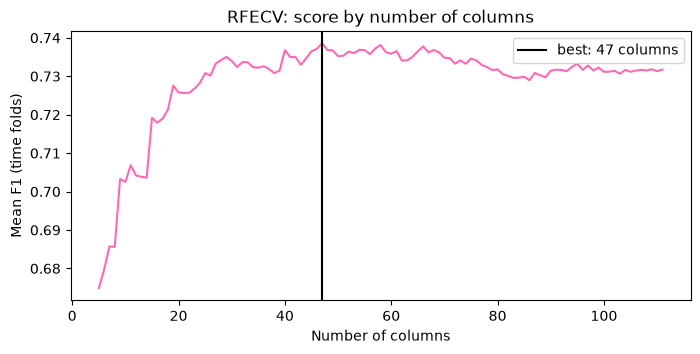

In [51]:
# To check the mean F1 for each number of columns:
scores = rfecv.cv_results_["mean_test_score"]
n_features = rfecv.cv_results_["n_features"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n_features, scores, color="hotpink")
ax.axvline(rfecv.n_features_, color="black", label=f"best: {rfecv.n_features_} columns")
ax.set_xlabel("Number of columns")
ax.set_ylabel("Mean F1 (time folds)")
ax.set_title("RFECV: score by number of columns")
ax.legend()
plt.show()

- By keeping only 47 columns, the score rises to it's maximum.

## 3.6. Embedded

Lasso is a L1 penalty. This logistic regression gives a coefficient weight to each column.

For those columns that are unhelpful, it gives them a 0 coefficient.

In [52]:
from sklearn.feature_selection import SelectFromModel

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # newer scikit-learn versions warn about the 'penalty' name
warnings.filterwarnings("ignore", category=UserWarning)

lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=42)
lasso_selector = SelectFromModel(lasso)
lasso_selector.fit(X_train_prep, y_train)

lasso_keep = X_train_prep.columns[lasso_selector.get_support()].tolist()
print("Columns kept by Lasso:", len(lasso_keep))
print("keep random_noise:", "num__random_noise" in lasso_keep)

Columns kept by Lasso: 44
keep random_noise: True


- Lasso keeps random_noise during the features as a test, because its a column of random numbers that have no relationship with the target.

A decision tree measures how much its column improves its splits. 

In [53]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=25, random_state=42)
tree_selector = SelectFromModel(tree, threshold="mean")
tree_selector.fit(X_train_prep, y_train)

tree_keep = X_train_prep.columns[tree_selector.get_support()].tolist()
print("Columns kept by the tree:", len(tree_keep))
print("keep random_noise:", "num__random_noise" in tree_keep)

Columns kept by the tree: 13
keep random_noise: False


In [54]:
# to check the 10 most important columns for the tree
importance = pd.Series(tree_selector.estimator_.feature_importances_, index=X_train_prep.columns)
importance = importance.sort_values(ascending=False).head(10)
print(importance.round(3))

log__purchase_count_365d                                0.622
log__spend_180d                                         0.074
log__spend_365d                                         0.051
num__margin_share                                       0.048
log__prior_mean_gap_days                                0.034
log__prior_std_gap_days                                 0.020
cat__purchase_month_1                                   0.019
cat__commercial_region_Region RG17: We Will See Later   0.018
log__value_per_detail                                   0.013
log__days_since_previous_purchase                       0.012
dtype: float64


- `purchase_count_365d`  has 62% of the importance. The tree confirms that the number of purchases in the last year is the strongest sign that a customer will come back.
- Two of our new features, `margin_share` and `value_per_detail`, are in the top 10.

## 3.7. Final feature set

Each method has weaknesses: 

- Filters: looks only at one column ate the time;
- RFECV: it depends on one model;
- Decision Trees: only sees the columns that it kept.

Therefore no method can decide alone, so we are going to count the votes of the method and keep the columns that at least two methods chose to keep.

In [55]:
votes = pd.DataFrame(index=X_train_prep.columns)
votes["filters"] = votes.index.isin(filter_keep)
votes["RFECV"] = votes.index.isin(rfe_keep)
votes["Lasso"] = votes.index.isin(lasso_keep)
votes["tree"] = votes.index.isin(tree_keep)
votes["total"] = votes.sum(axis=1)

selected = votes[votes["total"] >= 2].index.tolist()
print("Final number of columns:", len(selected), "of", X_train_prep.shape[1])
print("keep random_noise:", "num__random_noise" in selected)

votes.sort_values("total", ascending=False).astype(int).head(30)

Final number of columns: 54 of 111
keep random_noise: False


,filters,RFECV,Lasso,tree,total
log__value_per_detail,1,1,1,1,4
log__purchase_count_365d,1,1,1,1,4
cat__commercial_region_Region RG17: We Will See Later,1,1,1,1,4
log__prior_mean_gap_days,1,0,1,1,3
num__margin_share,1,0,1,1,3
log__prior_purchase_count,1,1,1,0,3
log__Total Bruto,1,1,0,1,3
log__discount_share,1,1,1,0,3
log__purchase_count_90d,1,1,1,0,3
log__spend_365d,1,0,1,1,3


In [56]:
# To check the train F1 and validation F1
from sklearn.metrics import f1_score

check ={}
for name, cols in[("all columns", list(X_train_prep.columns)), ("selected columns",selected)]:
    model = LogisticRegression(max_iter=2000)
    model.fit(X_train_prep[cols], y_train)
    check[name]= {
        "columns": len(cols),
        "train F1": f1_score(y_train, model.predict(X_train_prep[cols])),
        "validation F1": f1_score(y_val, model.predict(X_val_prep[cols])),
    }

pd.DataFrame(check).T.round(4)

,columns,train F1,validation F1
all columns,111.000,0.748,0.762
selected columns,54.000,0.744,0.778


- The validation F1 increases. The training F1 drops a little, so the gap between training and validation is not an problem (the removed columns were mostly noise. The model is simpler now.

In [57]:
# To keep only the selected columns:
X_train_sel = X_train_prep[selected]
X_val_sel = X_val_prep[selected]
X_test_sel = X_test_prep[selected]

print(X_train_sel.shape, X_val_sel.shape, X_test_sel.shape)

(5175, 54) (1294, 54) (986, 54)


# 4. Model and Assess Performance

## 4.1. Assessment and metric

Assessment strategy: test.csv contains purchases that happen after every purchase in train.csv, then our assessment must also predict the future from the past.

Time-based holdout: the model learns on the oldest 80% of train and is assessed on the most recent 20%.
Time-based cross-validation is on the training rows to compare models.

Metric: we will use F1 as the main metric.

The classes are almost balanced (56% and 44%), but predicting a repeat purchase for everyone already gives a high accuracy.
F1 combines precision (when we say "will buy again", how often we are right) and recall (how many of the customers who do buy again we find). For the company, both mistakes cost something: wasted actions on customers who will not come back, and missed customers who would.
We also report accuracy and ROC AUC (how well the model ranks customers by probability, independently of the 0.5 threshold).


In [58]:
#To define the cross-validation and a function that computes all the metrics:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

time_cv = TimeSeriesSplit(n_splits=5)

def validation_scores(model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        "F1": f1_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "ROC AUC": roc_auc_score(y, probabilities),
    }

## 4.2. Baseline

In [59]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_sel, y_train)

results = {"Baseline (always 1)": validation_scores(baseline, X_val_sel, y_val)}
pd.DataFrame(results).T.round(4)

,F1,precision,recall,accuracy,ROC AUC
Baseline (always 1),0.754,0.605,1.000,0.605,0.500


- Prediction of someone buying again already gives a high F1. However this is useless for the company because its not capable of identify a customer that might not come back, which must be clear in the model. 

## 4.3. Comparing logistic regression and Decision tree

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

candidates = {}
for C in [0.01, 0.1, 1, 10]:
    candidates[f"Logistic C={C}"] = LogisticRegression(C=C, max_iter=2000)
for depth in [3, 5, 7, 10]:
    candidates[f"Tree depth={depth}"] = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=25, random_state=42)

cv_rows = []
for name, model in candidates.items():
    cv = cross_validate(model, X_train_sel, y_train, cv=time_cv, scoring="f1", return_train_score=True)
    cv_rows.append({
        "model": name,
        "train F1": cv["train_score"].mean(),
        "CV F1": cv["test_score"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("model").round(4)
cv_results

,train F1,CV F1
model,,
Logistic C=0.01,0.726,0.751
Logistic C=0.1,0.741,0.740
Logistic C=1,0.749,0.738
Logistic C=10,0.747,0.732
Tree depth=3,0.699,0.718
Tree depth=5,0.738,0.710
Tree depth=7,0.755,0.709
Tree depth=10,0.769,0.706


- All the logistic regression versions have a higher CV F1 than all the trees.
- From tree dept=3 to depth=10, train F1 increases but CV F1 decreases. This means that the tree is memorizing the train data instead of learning rules from it. This is an example of overfitting.
- The simplest model is the best, a lower C makes it more stable.

In [61]:
# The best setting of each model will be fitted on the training rows and assess it on the validation rows
best_logistic = cv_results.filter(like="Logistic", axis=0)["CV F1"].idxmax()
best_tree = cv_results.filter(like="Tree", axis=0)["CV F1"].idxmax()
print("Best logistic regression:", best_logistic)
print("Best decision tree:      ", best_tree)

for name in [best_logistic, best_tree]:
    model = candidates[name]
    model.fit(X_train_sel, y_train)
    results[name] = validation_scores(model, X_val_sel, y_val)

pd.DataFrame(results).T.round(4)

Best logistic regression: Logistic C=0.01
Best decision tree:       Tree depth=3


,F1,precision,recall,accuracy,ROC AUC
Baseline (always 1),0.754,0.605,1.000,0.605,0.500
Logistic C=0.01,0.772,0.802,0.745,0.734,0.812
Tree depth=3,0.732,0.820,0.662,0.707,0.783


- The **logistic regression** is the best model again

## 4.4 Final model and predictions

In [62]:
chosen_name = best_logistic
chosen_model = candidates[chosen_name]

In [63]:
# For the final predictions, we are starting by re-fitting the preprocessor and the model on all train rows:
from sklearn.base import clone

X_full = pd.concat([X_train,X_val])
y_full = pd.concat([y_train, y_val])

final_preprocessor = clone(preprocessor)                 
X_full_prep = final_preprocessor.fit_transform(X_full)
X_test_final = final_preprocessor.transform(X_test)

final_columns = [col for col in selected if col in X_full_prep.columns]
print("Selected columns available:", len(final_columns), "of", len(selected))

final_model = clone(chosen_model)
final_model.fit(X_full_prep[final_columns], y_full)
print("Final model fitted on", len(y_full), "rows")

Selected columns available: 54 of 54
Final model fitted on 6469 rows


In [67]:
# Now lets predict every row of test.csv
test_predictions = final_model.predict(X_test_final[final_columns])

submission = pd.DataFrame({
    "ID": X_test_final.index,                    
    "repeat_purchase_90d": test_predictions,
})

# Same order of rows as the sample file
submission = sample_submission[["ID"]].merge(submission, on="ID", how="left")

print("Rows:", len(submission))
print("Missing predictions:", submission["repeat_purchase_90d"].isna().sum())
print("Share of 1s predicted:", round(submission["repeat_purchase_90d"].mean(), 3))

submission.to_csv("submission.csv", index=False)
submission.head()

Rows: 986
Missing predictions: 0
Share of 1s predicted: 0.658


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


- The file submission.csv has one prediction for each of the 986 test rows, with the ID unchanged and the same columns as sample_submission.csv.

- The model predicts to repeat a purchase for 66% of the test purchases, more than the 56% of train.